# 02. Mô tả chuỗi và bóc tách

Xu hướng, mùa vụ; nhận xét mô tả (không phân tích nhân quả).


In [1]:
import sys
sys.path.append('../src')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [2]:
df = pd.read_csv("../data/processed/cpi_monthly_clean.csv", parse_dates=["date"])
df.head()

,date,mom,pct,index
0,2006-01-01,101.2,1.2,100.000000
1,2006-02-01,102.1,2.1,102.100000
2,2006-03-01,99.5,-0.5,101.589500
3,2006-04-01,100.2,0.2,101.792679
4,2006-05-01,100.6,0.6,102.403435


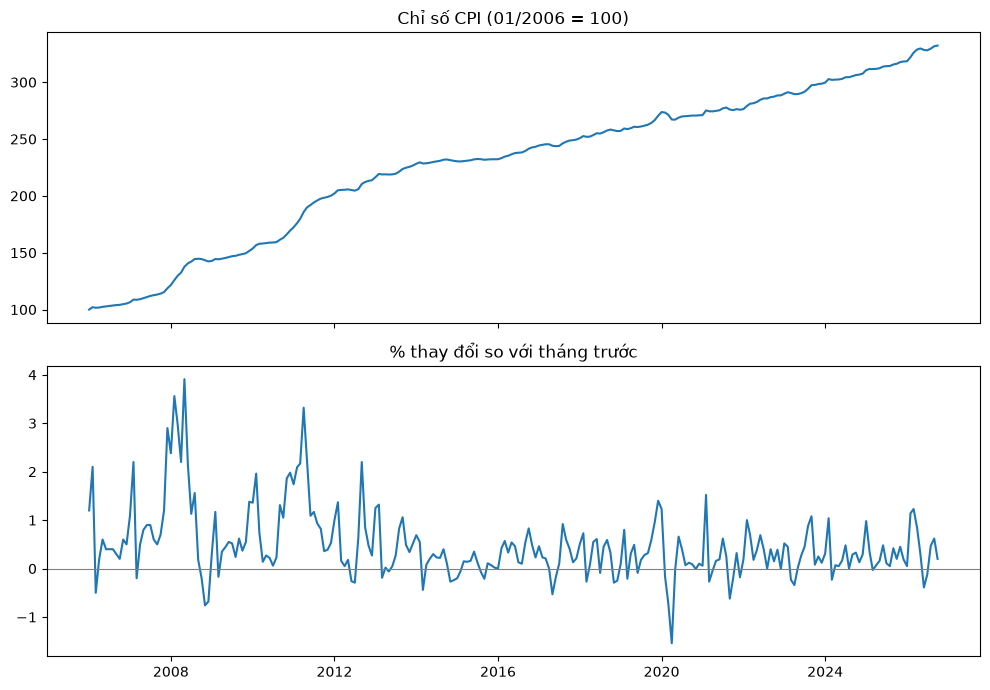

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

axes[0].plot(df["date"], df["index"])
axes[0].set_title("Chỉ số CPI (01/2006 = 100)")

axes[1].plot(df["date"], df["pct"])
axes[1].axhline(0, color="gray", linewidth=0.8)
axes[1].set_title("% thay đổi so với tháng trước")

plt.tight_layout()
plt.show()

In [ ]:
from cpi_forecast.analysis.decomposition import decompose

d = decompose(df["pct"].to_numpy(), period=12)

fig, axes = plt.subplots(4, 1, figsize=(10, 9), sharex=True)
axes[0].plot(df["date"], df["pct"]);        axes[0].set_title("% thay đổi (chuỗi gốc)")
axes[1].plot(df["date"], d["xu_huong"]);    axes[1].set_title("Xu hướng (trung bình trượt 12 tháng)")
axes[2].plot(df["date"], d["mua_vu"]);      axes[2].set_title("Mùa vụ")
axes[3].plot(df["date"], d["con_lai"]);     axes[3].set_title("Phần còn lại")
plt.tight_layout(); plt.show()

# Chỉ số mùa vụ theo từng tháng (12 giá trị)
thang = ["T1","T2","T3","T4","T5","T6","T7","T8","T9","T10","T11","T12"]
print(dict(zip(thang, d["mua_vu"][:12].round(2))))